# Interpreting GC content differences at polymorphic sites: generating figures

| Figure | Content |
|---|---|
| 1A | [A] vs [C] per individual, common vs rare SNPs (1000 Genomes) |
| 1B | GC% by MAF threshold (1000 Genomes) |
| 1C | GC% across fine MAF bins (1000 Genomes) |
| 2  | [A] vs [C] per individual in human, silkworm, maize, mouse |
| 3  | SFS and mean DAF by mutation type (1000 Genomes) |
| 4A–B | GC% by DAF stratum and MAF threshold: 1000 Genomes vs SLiM simulations |
| 4C | GC% across fine MAF bins (SLiM, mutation bias + gBGC) |
| S2 | As Fig. 3, CpG/TpG sites excluded |

**To run:** edit `DATA_DIR` / `FIG_DIR` (and file names in `PATHS` if needed), then run all cells.

In [1]:
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FixedLocator, FormatStrFormatter, MaxNLocator

# ---- Paths: edit these ----------------------------------------------------
DATA_DIR = Path("/Users/sheelchandra/Downloads")
IN_DIR = DATA_DIR / "base_comp_input_files"
FIG_DIR = DATA_DIR / "base_comp_output_files/base_comp_figs/"

PATHS = {
    # Sample annotations
    "1kg_samples":     DATA_DIR / "20130606_g1k_3202_samples_ped_population.txt",
    "silkworm_samples": IN_DIR / "silkworm sample names.xlsx",
    "maize_samples":   DATA_DIR / "Maize HapMap3 sample names.xlsx",
    # Per-individual allele counts at polymorphic sites
    "human_all":       IN_DIR / "nucleotide_proportions_all.txt",
    "human_common":    IN_DIR / "nucleotide_proportions_common.txt",
    "human_rare":      IN_DIR / "nucleotide_proportions_rare.txt",
    "silkworm_all":    IN_DIR / "silkworm_all_sums.txt",
    "silkworm_common": IN_DIR / "silkworm_common_sums.txt",
    "maize_all":       IN_DIR / "maize_all_sums.txt",
    "maize_common":    IN_DIR / "maize_common_sums.txt",
    "mouse_all":       IN_DIR / "mouse_all_sums.txt",
    "mouse_common":    IN_DIR / "mouse_common_sums.txt",
    # GC% by MAF threshold (maf0, maf1, maf3, maf5, maf10)
    "gc_thresh_1kg":        IN_DIR / "gc_by_maf_1KG.txt",
    "gc_thresh_slim_gbgc":  IN_DIR / "avg_gc_by_global_maf_bin_slim_mut_bias_and_gBGC.txt",
    "gc_thresh_slim_nogbgc": IN_DIR / "avg_gc_by_maf_slim_control_nogBGC.txt",
    # GC% per 0.5%-wide MAF bin
    "gc_maf_1kg":      IN_DIR / "avg_gc_by_maf_bin_fine_1KG.txt",
    "gc_maf_slim":     DATA_DIR / "base_comp_github/base_comp_input_files/avg_gc_by_maf_bin_fine_slim.txt",
    # Mean GC% / DAF by DAF stratum with bootstrap CIs
    "boot_gc_1kg":     IN_DIR / "bootstrap_av_GC.txt",
    "slim_daf_gbgc":   IN_DIR / "slim_gBGC_av_DAF.txt",
    "slim_daf_nogbgc": IN_DIR / "slim_control_av_DAF.txt",
    "boot_daf_all":    DATA_DIR / "base_comp_apr_26/bootstrap_av_DAF.txt",
    "boot_daf_no_cpg": IN_DIR / "supp/no_CpG_bootstrap_av_DAF.txt",
    # Polarized SNPs with per-population DAF
    "daf_all":         IN_DIR / "all_chrs_polarized.txt",
    "daf_no_cpg":      DATA_DIR / "base_comp_apr_26/all_chrs_polarized_no_CpG_TpG.txt",
}

# ---- Shared style ----------------------------------------------------------
POP_COLORS = {"EAS": "#00b4d8", "EUR": "#03045e", "AMR": "#0077b6",
              "SAS": "#90e0ef", "AFR": "#F73939"}
POPS = ["EAS", "EUR", "AMR", "SAS", "AFR"]
SLIM_POPS = {"p1": "AFR", "p2": "EUR", "p3": "EAS"}        # SLiM population IDs -> labels
GROUP_COLORS = {"Non-Bottlenecked": "#F73939", "Bottlenecked": "#3A6EA5"}
MUTATIONS = ["C>T", "C>A", "C>G", "T>C", "T>G", "T>A"]
MAF_THRESHOLDS = ["maf0", "maf1", "maf3", "maf5", "maf10"]
MAF_THRESHOLD_LABELS = ["None", "MAF≥1%", "MAF≥3%", "MAF≥5%", "MAF≥10%"]
SAVE_DPI = 300


def style_axes(ax, spine_width=2, labelsize=17, tick_width=3):
    ax.spines[:].set_linewidth(spine_width)
    ax.tick_params(axis="both", which="major", labelsize=labelsize, width=tick_width)


def save(fig, name, **kw):
    fig.savefig(FIG_DIR / name, dpi=SAVE_DPI, **kw)
    plt.show()

## Load data

In [2]:
def load_1kg_samples():
    samples = pd.read_csv(PATHS["1kg_samples"], sep=r"\s+")
    return (samples.drop(columns=["FamilyID", "FatherID", "MotherID", "Sex"])
                   .rename(columns={"SampleID": "Sample"}))


def _to_proportions(d):
    """Convert A/C/G/T allele counts to per-individual proportions (in place)."""
    bases = ["A", "C", "G", "T"]
    d[bases] = d[bases].div(d[bases].sum(axis=1), axis=0)
    return d


def load_human(variant_set, samples):
    """Per-individual base proportions (1000 Genomes) for 'all', 'common' or 'rare' SNPs."""
    d = pd.read_csv(PATHS[f"human_{variant_set}"], sep="\t").rename(columns={"SAMPLE": "Sample"})
    return _to_proportions(d).merge(samples, on="Sample", how="left")


def load_sums(path):
    """Per-individual base proportions from a *_sums.txt file (Sample, A, G, T, C counts)."""
    d = pd.read_csv(path, sep="\t", low_memory=False,
                    names=["Sample", "A", "G", "T", "C"], skiprows=1)
    return _to_proportions(d)


def load_gc_by_threshold_1kg():
    d = pd.read_csv(PATHS["gc_thresh_1kg"], sep="\t", header=None,
                    names=["MAF_bin", "AFR", "EUR", "AMR", "EAS", "SAS"])
    return d.set_index("MAF_bin").loc[MAF_THRESHOLDS]


def load_gc_by_threshold_slim(path):
    d = pd.read_csv(path, sep=r"\s+").set_index("MAF_bin").loc[MAF_THRESHOLDS]
    return d.rename(columns={f"GC_{p}": label for p, label in SLIM_POPS.items()})


samples_1kg = load_1kg_samples()

## Figure 1

### Fig. 1A: base composition per individual, common vs rare SNPs

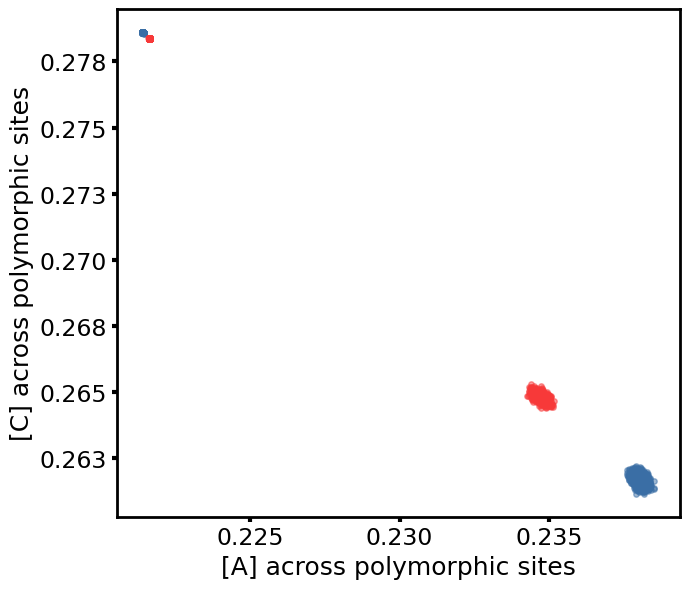

In [3]:
def plot_fig1a():
    fig, ax = plt.subplots(figsize=(7, 6))
    for variant_set in ("common", "rare"):
        d = load_human(variant_set, samples_1kg)
        is_afr = d["Superpopulation"] == "AFR"
        ax.scatter(d.loc[~is_afr, "A"], d.loc[~is_afr, "C"], color=GROUP_COLORS["Bottlenecked"],
                   alpha=0.5, s=15)
        ax.scatter(d.loc[is_afr, "A"], d.loc[is_afr, "C"], color=POP_COLORS["AFR"],
                   alpha=0.5, s=15)

    ax.xaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%.3f"))
    ax.set_xlabel("[A] across polymorphic sites", fontsize=18)
    ax.set_ylabel("[C] across polymorphic sites", fontsize=18)
    style_axes(ax)
    fig.tight_layout()
    save(fig, "Fig1A.png")


plot_fig1a()

### Fig. 1B: GC% by MAF threshold

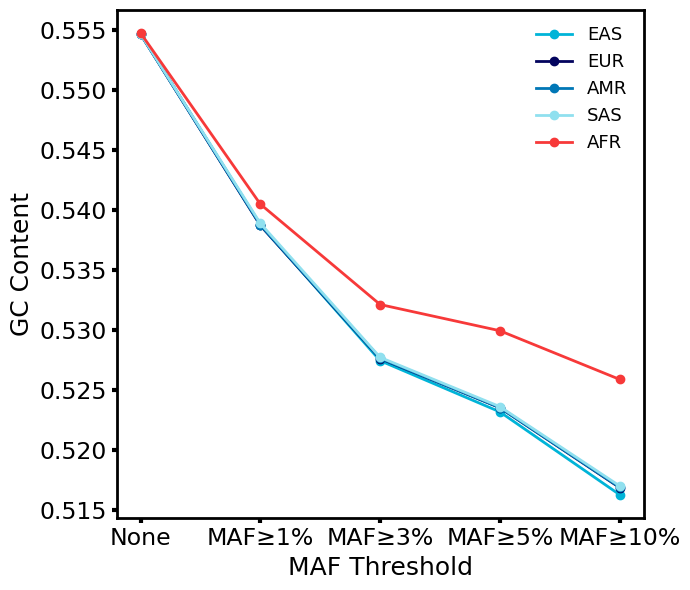

In [4]:
def draw_gc_by_threshold(ax, table, pops):
    """One line per population: GC% of SNPs passing each MAF threshold."""
    for p in pops:
        ax.plot(range(len(MAF_THRESHOLDS)), table[p], color=POP_COLORS[p],
                marker="o", label=p, linewidth=2, markersize=6)
    ax.set_xticks(range(len(MAF_THRESHOLDS)), MAF_THRESHOLD_LABELS)


def plot_fig1b():
    fig, ax = plt.subplots(figsize=(7, 6))
    draw_gc_by_threshold(ax, load_gc_by_threshold_1kg(), POPS)
    ax.set_xlabel("MAF Threshold", fontsize=18)
    ax.set_ylabel("GC Content", fontsize=18)
    ax.legend(fontsize=13, frameon=False)
    style_axes(ax)
    fig.tight_layout()
    save(fig, "Fig1B.png")


plot_fig1b()

### Fig. 1C (and Fig. 4C): GC% across fine MAF bins

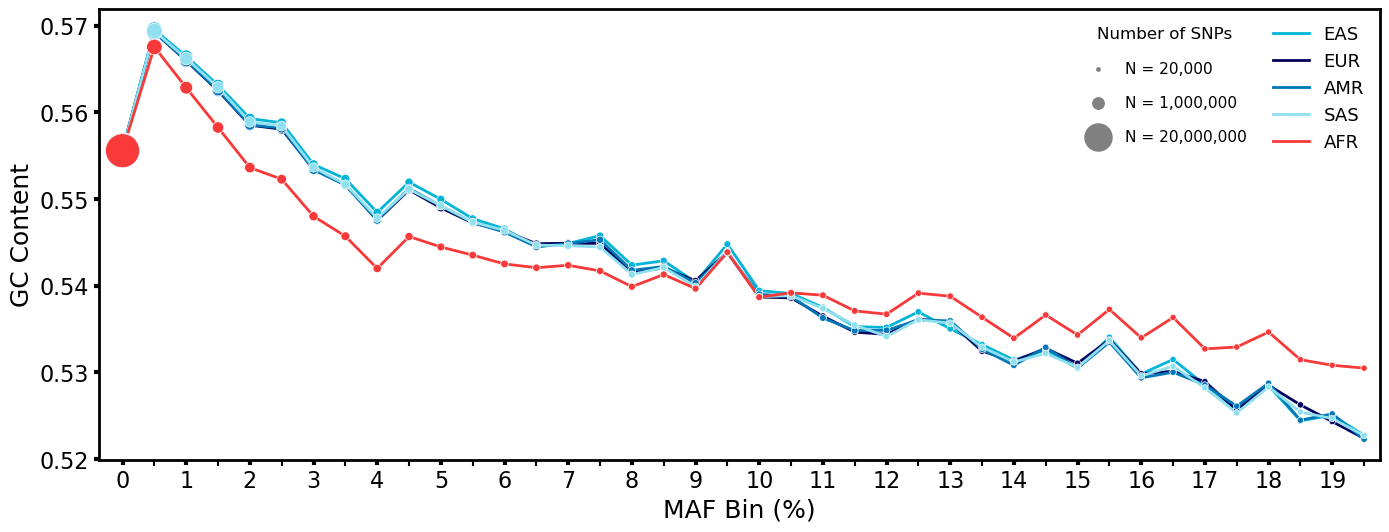

In [5]:
def _round_down_nice(x):
    """Round x down to the nearest 1/2/5 x 10^k (e.g. 8,342 -> 5,000)."""
    if x <= 0:
        return 0
    mag = 10 ** np.floor(np.log10(x))
    for m in (5, 2, 1):
        if x >= m * mag:
            return int(m * mag)
    return int(mag)


def plot_gc_by_maf_bin(path, pops, save_name, max_maf=0.20, size_range=(20, 600)):
    """Line + marker plot of GC% per MAF bin; marker area scales with sqrt(#SNPs)."""
    df = pd.read_csv(path, sep=r"\s+")
    df["maf_lower"] = df["MAF_bin"].str.split("-").str[0].astype(float)
    df = df[df["maf_lower"] < max_maf].sort_values("maf_lower").reset_index(drop=True)

    x = np.arange(len(df))
    lower_pct = np.round(df["maf_lower"].to_numpy() * 100, 6)    # 0, 0.5, 1, ...

    # Marker size: sqrt-scaled N on a common scale across populations
    n_all = df[[f"N_{p}" for p in pops]].to_numpy()
    n_min, n_max = n_all.min(), n_all.max()
    s_min, s_max = size_range

    def size_from_n(n):
        frac = (np.sqrt(n) - np.sqrt(n_min)) / (np.sqrt(n_max) - np.sqrt(n_min))
        return s_min + np.clip(frac, 0, 1) * (s_max - s_min)

    fig, ax = plt.subplots(figsize=(14, 5.5))
    for p in pops:
        ax.plot(x, df[f"GC_{p}"], color=POP_COLORS[p], lw=2, zorder=2, label=p)
        ax.scatter(x, df[f"GC_{p}"], s=size_from_n(df[f"N_{p}"]), color=POP_COLORS[p],
                   edgecolor="white", linewidth=0.5, zorder=3)

    # x-axis: labelled tick every 1% (lower bound of the bin)
    major = np.flatnonzero(np.isclose(lower_pct % 1, 0))
    ax.set_xticks(major, [f"{lower_pct[i]:.0f}" for i in major])
    ax.set_xticks(x, minor=True)
    ax.tick_params(axis="x", which="minor", length=4, width=1.5)
    ax.set_xlim(-0.75, len(df) - 0.5)
    ax.set_xlabel("MAF Bin (%)", fontsize=18)
    ax.set_ylabel("GC Content", fontsize=18)
    style_axes(ax, labelsize=16)

    # Legend 1: population colours
    ax.add_artist(ax.legend(fontsize=13, frameon=False, loc="upper right"))

    # Legend 2: marker size, three log-spaced round numbers spanning the observed N
    example_n = sorted({_round_down_nice(v)
                        for v in np.geomspace(max(n_min, 1), n_max, num=3)})
    size_handles = [ax.scatter([], [], s=size_from_n(n), color="gray", edgecolor="white",
                               label=f"N = {n:,}") for n in example_n]
    ax.legend(handles=size_handles, fontsize=11, frameon=False, bbox_to_anchor=(0.75, 0.65),
              title="Number of SNPs", title_fontsize=12, labelspacing=1.25, borderpad=1)

    fig.tight_layout()
    save(fig, save_name)


plot_gc_by_maf_bin(PATHS["gc_maf_1kg"], POPS, "Fig1C.png")

## Figure 2: base composition per individual across species

Each individual appears twice per panel, once from all SNPs and once from common SNPs
(MAF ≥ 5%), which gives the two clusters. Colour shows bottleneck status only.

In [6]:
def load_species(name, annotate):
    """Load all + common SNP sets for one species; `annotate` adds a 'Group' column (and filters)."""
    parts = []
    for variant_set, label in (("all", "All"), ("common", "Common (MAF≥5%)")):
        d = annotate(load_sums(PATHS[f"{name}_{variant_set}"]))
        d["VariantSet"] = label
        parts.append(d)
    return pd.concat(parts, ignore_index=True)


def bottleneck_group(is_non_bottlenecked):
    return np.where(is_non_bottlenecked, "Non-Bottlenecked", "Bottlenecked")


# Silkworm: wild = non-bottlenecked; domesticated = bottlenecked
silk_pops = pd.read_excel(PATHS["silkworm_samples"])[["Sample", "Population"]]

def annotate_silkworm(d):
    d = d.merge(silk_pops, on="Sample", how="inner")
    d["Group"] = bottleneck_group(d["Population"] == "Wild")
    return d

# Maize: Z. mays ssp. mays (domesticated) = bottlenecked; teosintes etc. = non-bottlenecked
maize_pops = pd.read_excel(PATHS["maize_samples"], sheet_name="Sheet7")

def annotate_maize(d):
    d = (d.merge(maize_pops, left_on="Sample", right_on="Prefixed_Taxon", how="inner")
          .dropna(subset=["Species"])
          .drop(columns="Prefixed_Taxon"))
    d["Group"] = bottleneck_group(d["Species"] != " Z. mays spp. Mays")   
    return d

# Mouse: M. m. castaneus (Mmc) = non-bottlenecked; M. spretus excluded from this analysis
MOUSE_SPRETUS = [f"Ms_SPRE{i}_SP{sp}.variant9"
                 for i, sp in enumerate([36, 39, 41, 51, 62, 68, 69, 70], start=1)]

def annotate_mouse(d):
    d = d[~d["Sample"].isin(MOUSE_SPRETUS)].copy()
    d["Population"] = d["Sample"].str[:3]
    d["Group"] = bottleneck_group(d["Population"] == "Mmc")
    return d


def load_human_species():
    parts = []
    for variant_set, label in (("all", "All"), ("common", "Common (MAF≥5%)")):
        d = load_human(variant_set, samples_1kg)
        d["Group"] = bottleneck_group(d["Superpopulation"] == "AFR")
        d["VariantSet"] = label
        parts.append(d)
    return pd.concat(parts, ignore_index=True)


species_panels = {
    "Human":    load_human_species(),
    "Silkworm": load_species("silkworm", annotate_silkworm),
    "Maize":    load_species("maize", annotate_maize),
    "Mouse":    load_species("mouse", annotate_mouse),
}

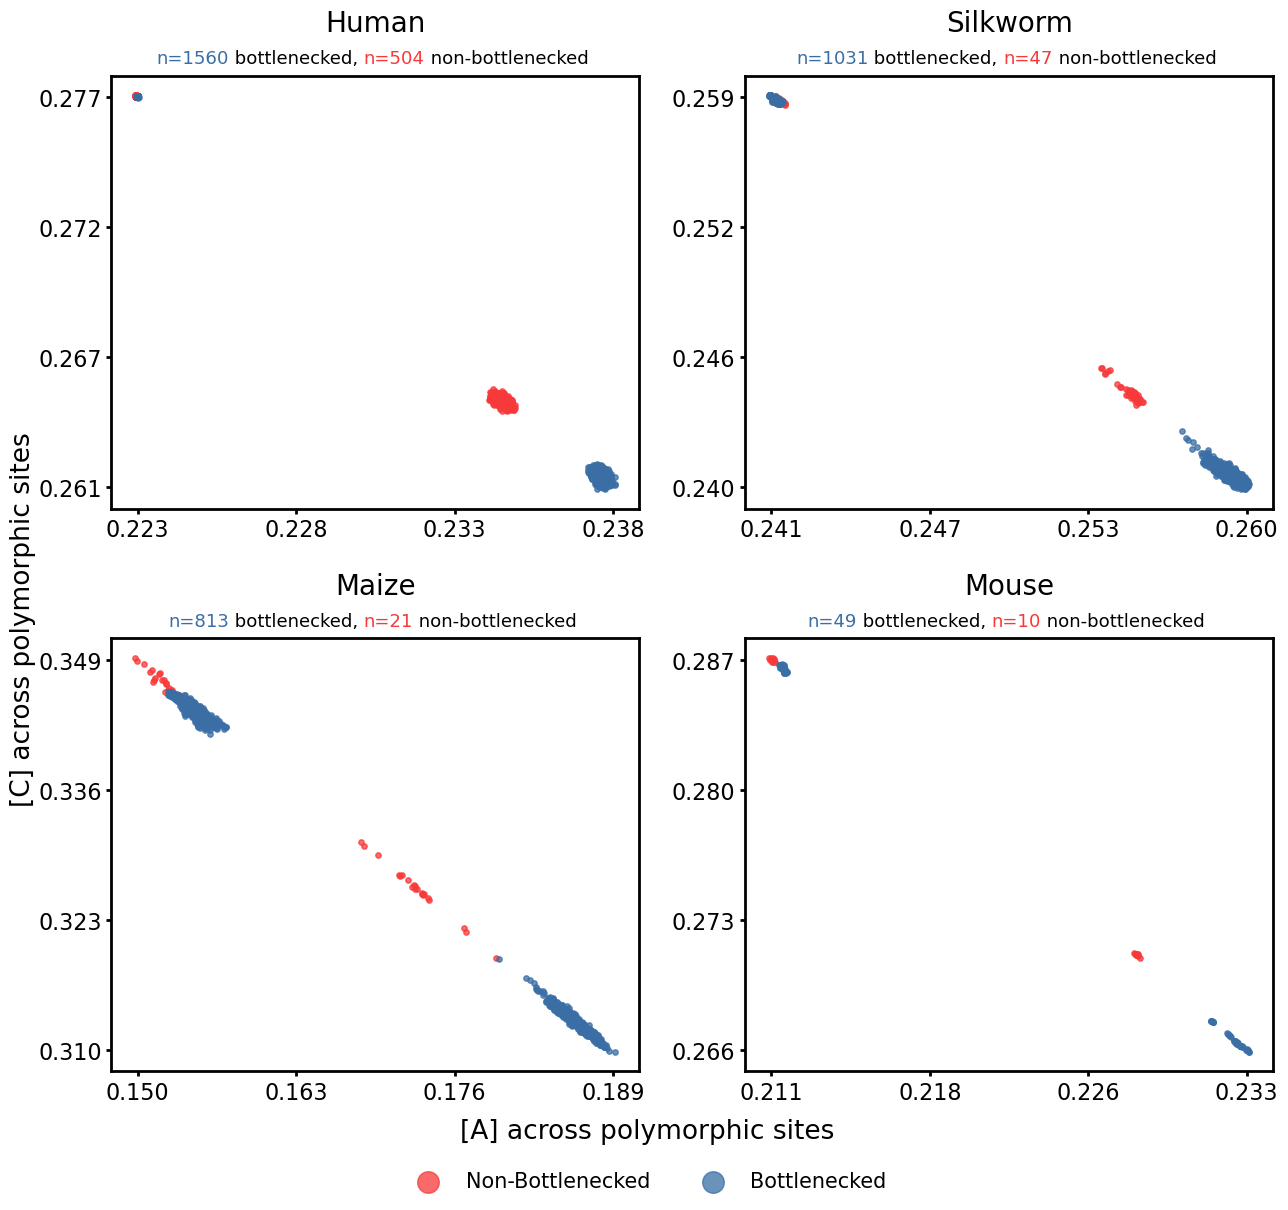

In [7]:
def colored_subtitle(ax, parts, y, fontsize):
    """Centered line of differently coloured text runs (axes-fraction coords).
    `parts` is a list of (text, colour). Call after the final layout so widths are correct."""
    renderer = ax.figure.canvas.get_renderer()
    texts = []
    for text, color in parts:
        t = ax.text(0, y, text, transform=ax.transAxes, fontsize=fontsize,
                    color=color, ha="left", va="bottom")
        width = t.get_window_extent(renderer).transformed(ax.transAxes.inverted()).width
        texts.append((t, width))
    x = 0.5 - sum(w for _, w in texts) / 2
    for t, width in texts:
        t.set_position((x, y))
        x += width


def set_uniform_ticks(ax, n=4):
    """n evenly spaced ticks inset 5% from each axis limit, 3-decimal labels."""
    for axis, (lo, hi) in ((ax.xaxis, ax.get_xlim()), (ax.yaxis, ax.get_ylim())):
        axis.set_major_locator(FixedLocator(np.linspace(lo + 0.05 * (hi - lo), hi - 0.05 * (hi - lo), n)))
        axis.set_major_formatter(FormatStrFormatter("%.3f"))


def plot_fig2():
    fig, axes = plt.subplots(2, 2, figsize=(13, 12.5))
    counts = []
    for i, (ax, (title, d)) in enumerate(zip(axes.flat, species_panels.items())):
        for group, color in GROUP_COLORS.items():
            sub = d[d["Group"] == group]
            ax.scatter(sub["A"], sub["C"], color=color, alpha=0.75, s=15,
                       label=group if i == 0 else None)
        counts.append([d.loc[d["Group"] == g, "Sample"].nunique()
                       for g in ("Bottlenecked", "Non-Bottlenecked")])
        ax.set_title(title, fontsize=20, pad=32)       
        style_axes(ax, labelsize=16, tick_width=2)
        set_uniform_ticks(ax)

    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center", bbox_to_anchor=(0.5, 0.05),
               ncol=2, fontsize=15, markerscale=4, frameon=False)
    fig.tight_layout(rect=[0.02, 0.10, 1, 1])
    fig.subplots_adjust(hspace=0.3, wspace=0.2)

    fig.canvas.draw()          
    for ax, (n_bottle, n_non) in zip(axes.flat, counts):
        colored_subtitle(ax, [(f"n={n_bottle}", GROUP_COLORS["Bottlenecked"]),
                              (" bottlenecked, ", "black"),
                              (f"n={n_non}", GROUP_COLORS["Non-Bottlenecked"]),
                              (" non-bottlenecked ", "black")], y=1.02, fontsize=13)

    fig.supxlabel("[A] across polymorphic sites", fontsize=19, y=0.08)
    fig.supylabel("[C] across polymorphic sites", fontsize=19, x=0.01)
    save(fig, "Fig2.png")


plot_fig2()

## Figure 3 and Fig. S2: SFS and average DAF by mutation type

Mutations are collapsed by strand (e.g. G>A is counted as C>T). 

In [8]:
STRAND_PAIRS = {
    "C>T": ("C>T", "G>A"),
    "C>A": ("C>A", "G>T"),
    "C>G": ("C>G", "G>C"),
    "T>C": ("T>C", "A>G"),
    "T>G": ("T>G", "A>C"),
    "T>A": ("T>A", "A>T"),
}
DAF_COLUMNS = ["Mutation", "DAF_AFR", "DAF_AMR", "DAF_EUR", "DAF_EAS", "DAF_SAS"]
BIN_WIDTH = 0.05
DAF_BINS = np.clip(np.arange(0.0, 1.0 + BIN_WIDTH, BIN_WIDTH), 0.0, 1.0)   # 20 bins


def compute_sfs(path, has_header):
    """Return {mutation type: DataFrame(bins x populations)} of the fraction of SNPs per DAF bin.

    Bins are [lo, hi), except the last, which is [0.95, 1]. The denominator is all SNPs of
    that mutation type.
    """
    snps = pd.read_csv(path, sep="\t", header=0 if has_header else None)
    snps.columns = DAF_COLUMNS
    snps["Mutation"] = snps["Mutation"].str.upper()

    sfs = {}
    for mut, pair in STRAND_PAIRS.items():
        sub = snps[snps["Mutation"].isin(pair)]
        sfs[mut] = pd.DataFrame({
            p: np.histogram(sub[f"DAF_{p}"].dropna(), bins=DAF_BINS)[0] / len(sub)
            for p in POPS
        })
    return sfs


def _draw_break_marks(ax_top, ax_bottom, d=0.015):
    """Diagonal // marks on both sides of a broken y-axis."""
    kw = dict(color="k", clip_on=False, linewidth=1.5)
    for xs in ((-d, d), (1 - d, 1 + d)):
        ax_top.plot(xs, (-d, d), transform=ax_top.transAxes, **kw)
        ax_bottom.plot(xs, (1 - d, 1 + d), transform=ax_bottom.transAxes, **kw)


def draw_sfs_grid(fig, spec, sfs, bottom_ylim=0.03, top_ylim=(0.88, 0.94),
                  tick_fs=15, title_fs=18, xlabel_pad=0.04):
    """Panel A: 3x2 grid of broken-y-axis SFS bar plots, one per mutation type."""
    n_bins = len(DAF_BINS) - 1
    x = np.arange(n_bins)
    bar_w = 0.8 / len(POPS)
    offsets = np.linspace(-0.4 + bar_w / 2, 0.4 - bar_w / 2, len(POPS))
    lower_pct = np.round(DAF_BINS[:-1] * 100, 6)                  # 0, 5, ..., 95
    major = np.flatnonzero(np.isclose(lower_pct % 10, 0))          # label 0, 10, ..., 90

    outer = gridspec.GridSpecFromSubplotSpec(3, 2, subplot_spec=spec, hspace=0.25, wspace=0.22)
    for idx, mut in enumerate(MUTATIONS):
        row, col = divmod(idx, 2)
        inner = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[row, col],
                                                 height_ratios=(1, 2), hspace=0.05)
        ax_top = fig.add_subplot(inner[0])
        ax_bot = fig.add_subplot(inner[1], sharex=ax_top)

        for off, p in zip(offsets, POPS):
            for ax in (ax_top, ax_bot):
                ax.bar(x + off, sfs[mut][p], width=bar_w, color=POP_COLORS[p], label=p)

        ax_top.set_ylim(*top_ylim)
        ax_bot.set_ylim(0, bottom_ylim)
        ax_top.yaxis.set_major_locator(MaxNLocator(nbins=3, prune="lower"))
        ax_bot.yaxis.set_major_locator(MaxNLocator(nbins=3, prune="upper"))
        ax_top.spines["bottom"].set_visible(False)
        ax_bot.spines["top"].set_visible(False)
        _draw_break_marks(ax_top, ax_bot)
        ax_top.set_title(mut, fontsize=title_fs)

        ax_top.tick_params(axis="x", which="both", bottom=False, labelbottom=False)
        ax_bot.set_xticks(major, [f"{lower_pct[i]:.0f}" for i in major] if row == 2 else [])
        ax_bot.set_xticks(x, minor=True)
        ax_bot.tick_params(axis="x", which="minor", length=3, width=1)
        for ax in (ax_top, ax_bot):
            style_axes(ax, spine_width=1.5, labelsize=tick_fs, tick_width=1.2)

    box = spec.get_position(fig)
    fig.text(box.x0 - 0.03, (box.y0 + box.y1) / 2, "SNP Density",
             va="center", rotation="vertical", fontsize=20)
    fig.text((box.x0 + box.x1) / 2, box.y0 - xlabel_pad, "DAF Bin (%)", ha="center", fontsize=20)
    return ax_bot.get_legend_handles_labels()


def draw_mean_daf_grid(fig, spec, boot, stratum_labels,
                       pops=("AFR", "EAS", "EUR", "AMR", "SAS")):
    """Panel B: 2x2 grid of mean DAF (95% bootstrap CI) per mutation type, one panel per DAF stratum."""
    x = np.arange(len(MUTATIONS))
    offsets = np.linspace(-0.25, 0.25, len(pops))
    gs = gridspec.GridSpecFromSubplotSpec(2, 2, subplot_spec=spec, hspace=0.2, wspace=0.2)

    for idx, (stratum, title) in enumerate(stratum_labels.items()):
        ax = fig.add_subplot(gs[divmod(idx, 2)])
        sub = boot[boot["Stratum"] == stratum]
        for off, p in zip(offsets, pops):
            d = sub[sub["Population"] == p].set_index("MutClass").reindex(MUTATIONS)
            ax.errorbar(x + off, d["mean_DAF"],
                        yerr=[d["mean_DAF"] - d["CI_low"], d["CI_high"] - d["mean_DAF"]],
                        fmt="o", color=POP_COLORS[p], markersize=7, capsize=3, linewidth=1.2)

        bottom_row, left_col = idx >= 2, idx % 2 == 0
        ax.set_xticks(x, MUTATIONS if bottom_row else [])
        if bottom_row:
            ax.set_xlabel("Mutation Type", fontsize=20)
        if left_col:
            ax.set_ylabel("Average DAF", fontsize=20)
        ax.set_title(title, fontsize=18)
        style_axes(ax, spine_width=3)


def make_sfs_daf_figure(daf_path, daf_has_header, boot_path, snp_counts, save_name):
    """Two-panel figure: SFS by mutation type (A) and mean DAF by DAF stratum (B).

    snp_counts: number of SNPs in each stratum, in the order
                (DAF<5%, 5%<=DAF<=95%, DAF>95%, all), used in the panel B titles.
    """
    sfs = compute_sfs(daf_path, daf_has_header)
    boot = pd.read_csv(boot_path, sep="\t")
    n_low, n_mid, n_high, n_all = snp_counts
    stratum_labels = {                                    # Stratum value from file is panel title
        "DAF<5%":       f"DAF < 5% (#SNPs={n_low:,})",
        "5%<=DAF<=95%": f"5% ≤ DAF ≤ 95% (#SNPs={n_mid:,})",
        "DAF>95%":      f"DAF > 95% (#SNPs={n_high:,})",
        "All":          f"All SNPs (#SNPs={n_all:,})",
    }

    fig = plt.figure(figsize=(28, 15))
    outer = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.05, 1], wspace=0.2)
    handles, labels = draw_sfs_grid(fig, outer[0], sfs)
    draw_mean_daf_grid(fig, outer[1], boot, stratum_labels)

    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.0),
               ncol=len(POPS), fontsize=20, frameon=False)
    save(fig, save_name, bbox_inches="tight")

### Fig. 3: all SNPs

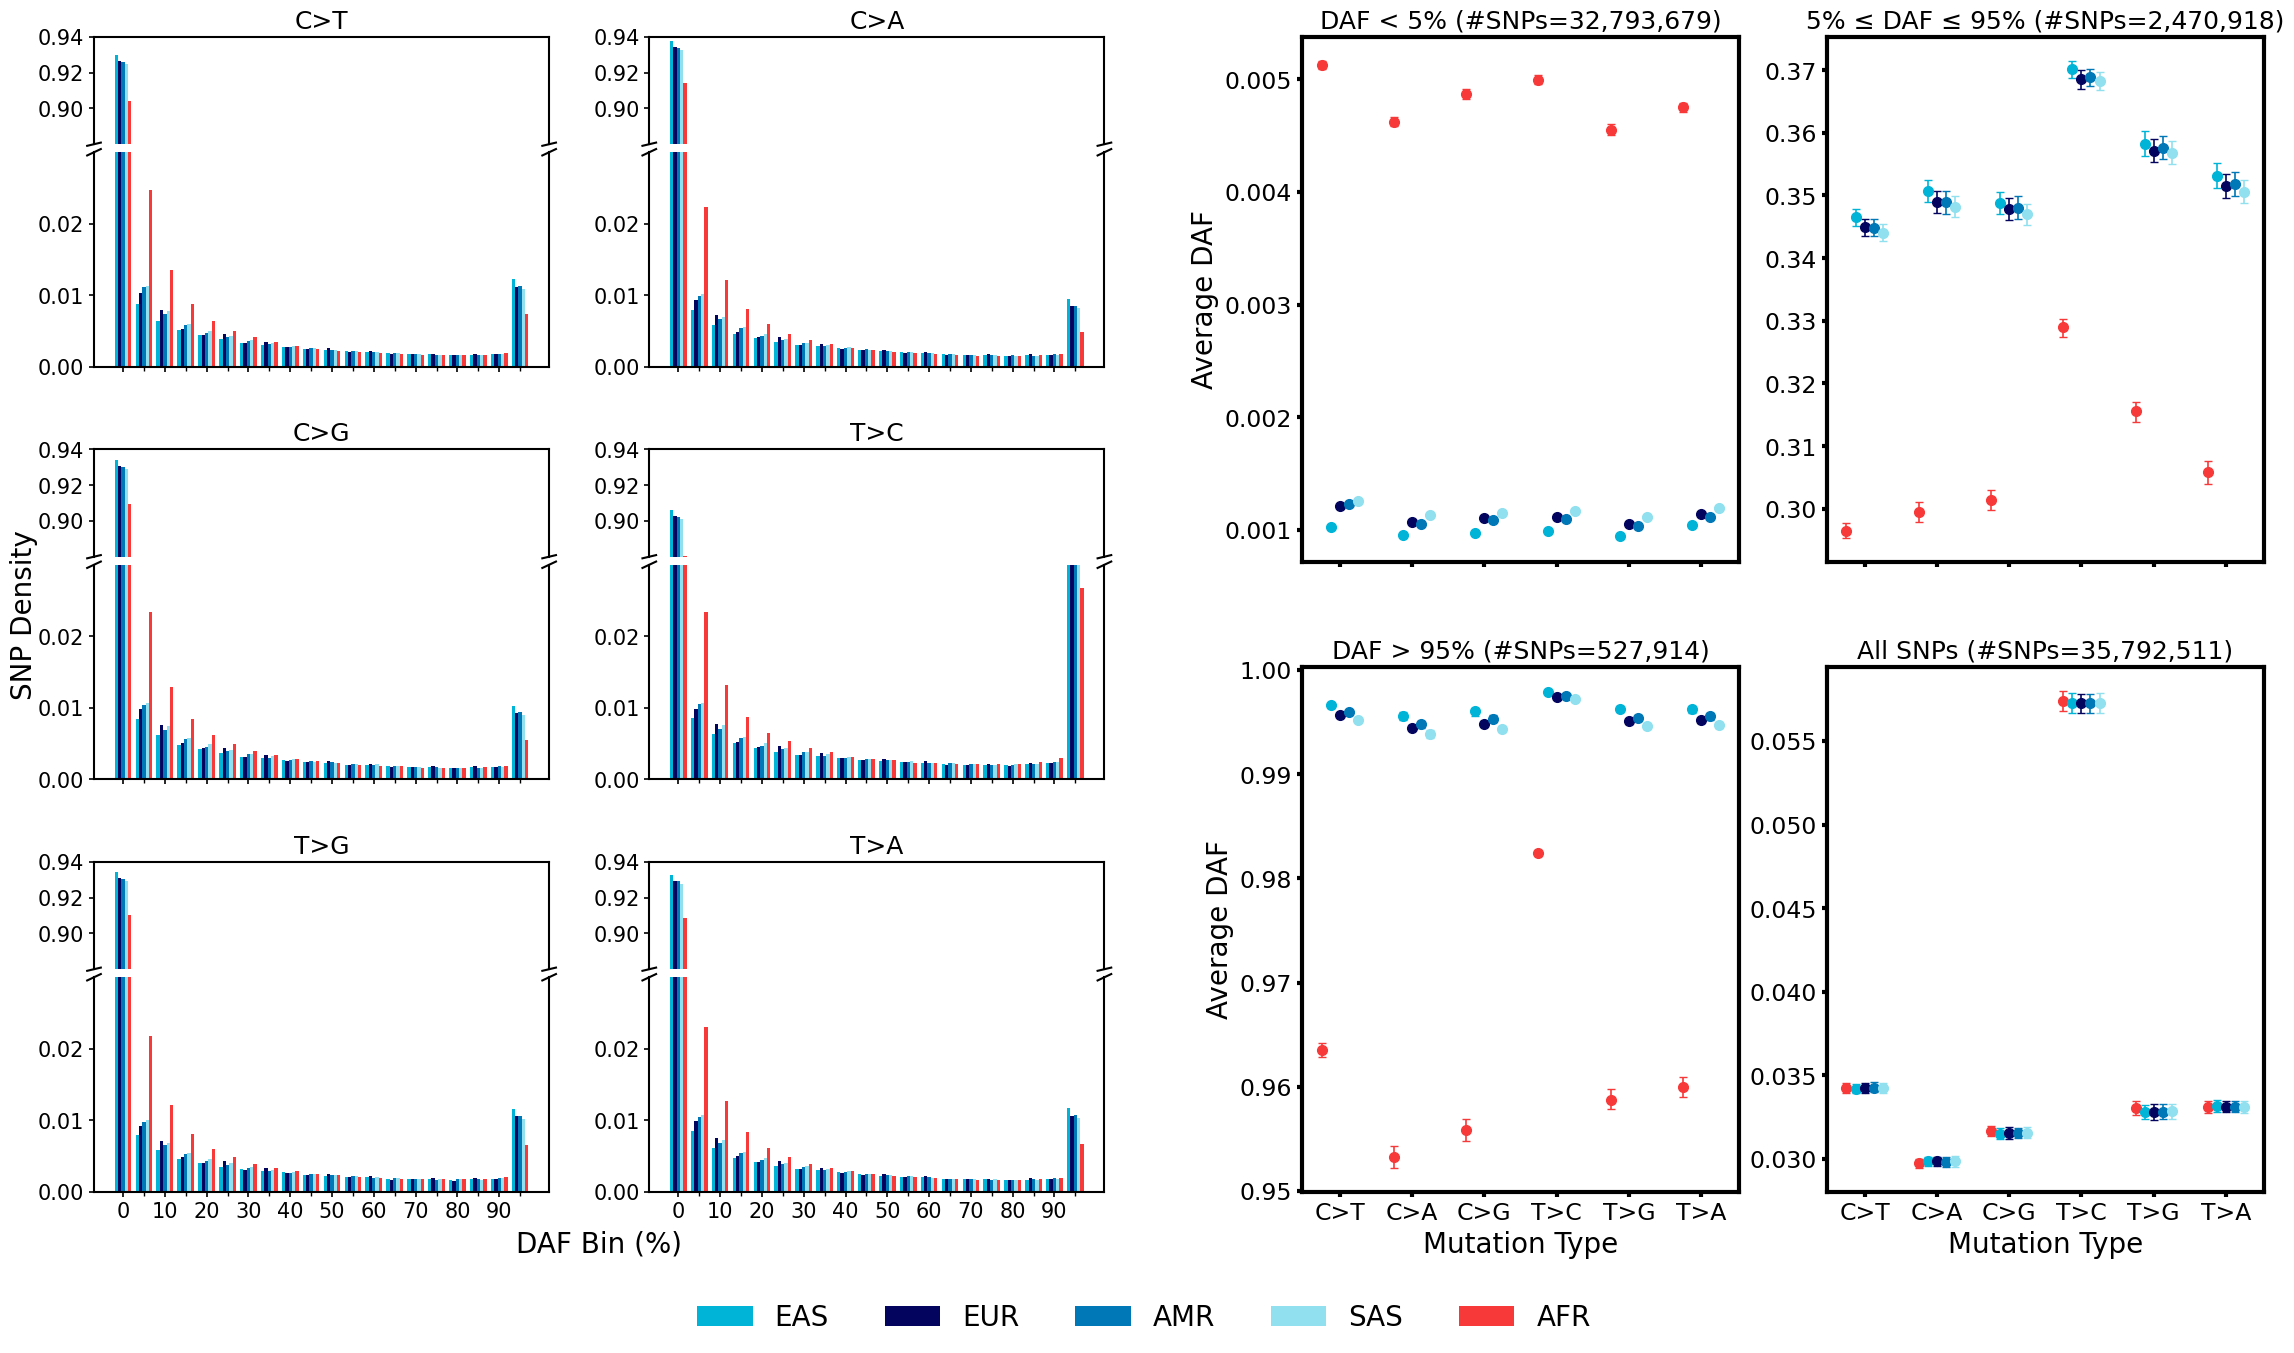

In [9]:
make_sfs_daf_figure(
    PATHS["daf_all"], daf_has_header=True, boot_path=PATHS["boot_daf_all"],
    snp_counts=(32_793_679, 2_470_918, 527_914, 35_792_511),
    save_name="Fig3.png",
)

## Figure 4: 1000 Genomes vs SLiM simulations

Row A: mean GC% (95% CI) by DAF stratum. Row B: GC% by MAF threshold.
Columns: 1000 Genomes; mutation bias + gBGC; mutation bias only.

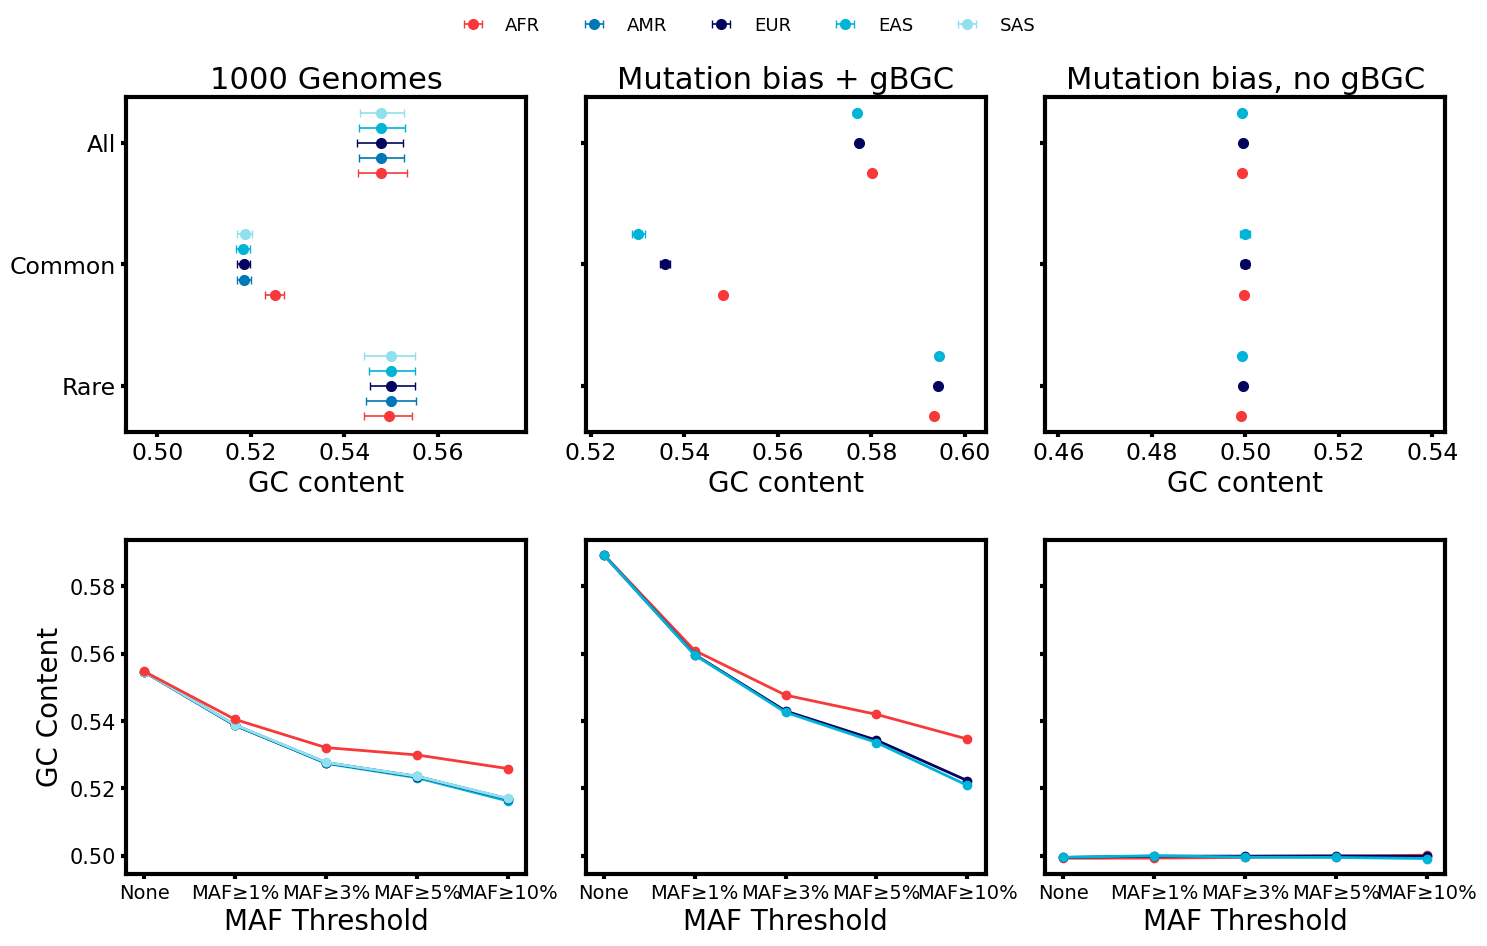

In [10]:
STRATUM_NAMES = {   # stratum labels used in the input files are plot labels
    "rare": "Rare", "mid": "Common", "all": "All",
    "DAF < 5% & DAF>95%": "Rare", "5%<=DAF<=95%": "Common", "All": "All",
}
STRATUM_ORDER = ["Rare", "Common", "All"]


def slim_gc_by_stratum(path):
    """Mean GC% (and CI) per population x DAF stratum from SLiM mean DAFs of S>W and W>S SNPs.

    The GC fraction is 1 - DAF for S>W SNPs (derived allele is A/T) and DAF for W>S SNPs. The two
    classes are averaged weighting by SNP count; rare-low and rare-high bins are merged into 'rare'
    the same way.
    """
    df = pd.read_csv(path, sep="\t")
    rows = []
    for (pop, bin_label), g in df.groupby(["Population", "Bin"]):
        sw = g[g["Mutation"] == "S>W"].iloc[0]
        ws = g[g["Mutation"] == "W>S"].iloc[0]
        n_sw, n_ws = sw["Total_SNPs"], ws["Total_SNPs"]
        n = n_sw + n_ws
        rows.append({
            "Population": pop,
            "Bin": "rare" if bin_label in ("rare-low", "rare-high") else bin_label,
            "mean_GC": ((1 - sw["Mean_DAF"]) * n_sw + ws["Mean_DAF"] * n_ws) / n,
            "CI_low":  ((1 - sw["CI_upper"]) * n_sw + ws["CI_lower"] * n_ws) / n,
            "CI_high": ((1 - sw["CI_lower"]) * n_sw + ws["CI_upper"] * n_ws) / n,
            "n_SNPs": n,
        })
    res = pd.DataFrame(rows)

    # SNP-weighted mean within each (population, stratum)
    stats = ["mean_GC", "CI_low", "CI_high"]
    res[stats] = res[stats].mul(res["n_SNPs"], axis=0)
    res = res.groupby(["Population", "Bin"], as_index=False)[stats + ["n_SNPs"]].sum()
    res[stats] = res[stats].div(res["n_SNPs"], axis=0)
    res["Stratum"] = res["Bin"].map(STRATUM_NAMES)
    return res


def load_1kg_gc_by_stratum():
    d = pd.read_csv(PATHS["boot_gc_1kg"], sep="\t")
    d["Stratum"] = d["Stratum"].map(STRATUM_NAMES)
    return d


def draw_gc_by_stratum(ax, df, pops, xlim):
    """Horizontal dot-and-CI plot: one row per DAF stratum, populations offset vertically."""
    offsets = np.linspace(-0.25, 0.25, len(pops))
    for off, p in zip(offsets, pops):
        d = df[df["Population"] == p].set_index("Stratum").reindex(STRATUM_ORDER)
        ax.errorbar(d["mean_GC"], np.arange(len(STRATUM_ORDER)) + off,
                    xerr=[d["mean_GC"] - d["CI_low"], d["CI_high"] - d["mean_GC"]],
                    fmt="o", color=POP_COLORS[p], markersize=7, capsize=3, linewidth=1.2, label=p)
    ax.set_xlim(*xlim)
    ax.set_yticks(range(len(STRATUM_ORDER)), STRATUM_ORDER)


def plot_fig4ab():
    sim_pops = list(SLIM_POPS.values())                    # AFR, EUR, EAS
    columns = [
        # title, GC-by-stratum table, GC-by-threshold table, populations
        ("1000 Genomes", load_1kg_gc_by_stratum(), load_gc_by_threshold_1kg(),
         ["AFR", "AMR", "EUR", "EAS", "SAS"]),
        ("Mutation bias + gBGC", slim_gc_by_stratum(PATHS["slim_daf_gbgc"]),
         load_gc_by_threshold_slim(PATHS["gc_thresh_slim_gbgc"]), sim_pops),
        ("Mutation bias, no gBGC", slim_gc_by_stratum(PATHS["slim_daf_nogbgc"]),
         load_gc_by_threshold_slim(PATHS["gc_thresh_slim_nogbgc"]), sim_pops),
    ]

    # Row A: same x-range width in every panel, each centred on its own data
    spans = [(d["CI_low"].min(), d["CI_high"].max()) for _, d, _, _ in columns]
    width = 1.3 * max(hi - lo for lo, hi in spans)

    fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharey="row")
    for col, ((title, by_stratum, by_threshold, pops), (lo, hi)) in enumerate(zip(columns, spans)):
        ax_a, ax_b = axes[0, col], axes[1, col]
        center = (lo + hi) / 2
        draw_gc_by_stratum(ax_a, by_stratum, pops, (center - width / 2, center + width / 2))
        ax_a.set_title(title, fontsize=22)
        ax_a.set_xlabel("GC content", fontsize=20)
        style_axes(ax_a, spine_width=3)

        # 1000 Genomes lines drawn in the same order as Fig. 1B
        draw_gc_by_threshold(ax_b, by_threshold, POPS if col == 0 else pops)
        ax_b.set_xlabel("MAF Threshold", fontsize=20)
        style_axes(ax_b, spine_width=3, labelsize=14)
        if col > 0:
            ax_a.tick_params(axis="y", labelleft=False)

    axes[1, 0].set_ylabel("GC Content", fontsize=20)
    axes[1, 0].tick_params(axis="y", labelsize=15)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, fontsize=13, frameon=False, loc="lower center",
               bbox_to_anchor=(0.5, 1), ncol=5)
    fig.tight_layout(h_pad=3)
    save(fig, "Fig4.png", bbox_inches="tight")


plot_fig4ab()

### Fig. 4C: GC% across fine MAF bins, mutation bias + gBGC simulation

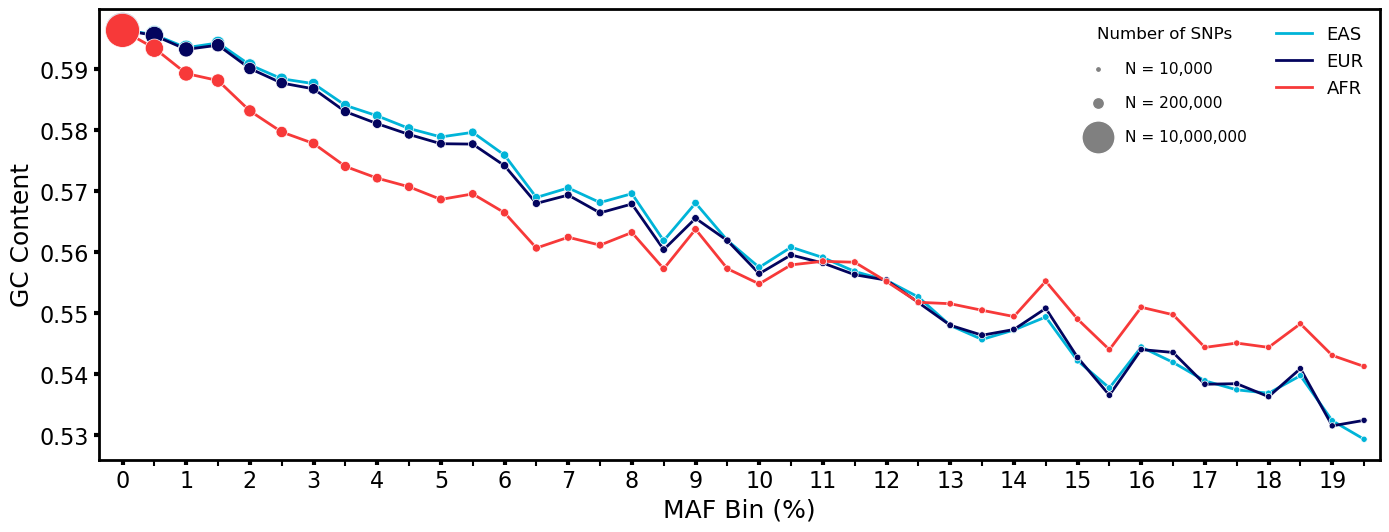

In [11]:
plot_gc_by_maf_bin(PATHS["gc_maf_slim"], ["EAS", "EUR", "AFR"], "Fig4C.png")

## Fig. S2: as Fig. 3, CpG/TpG sites excluded

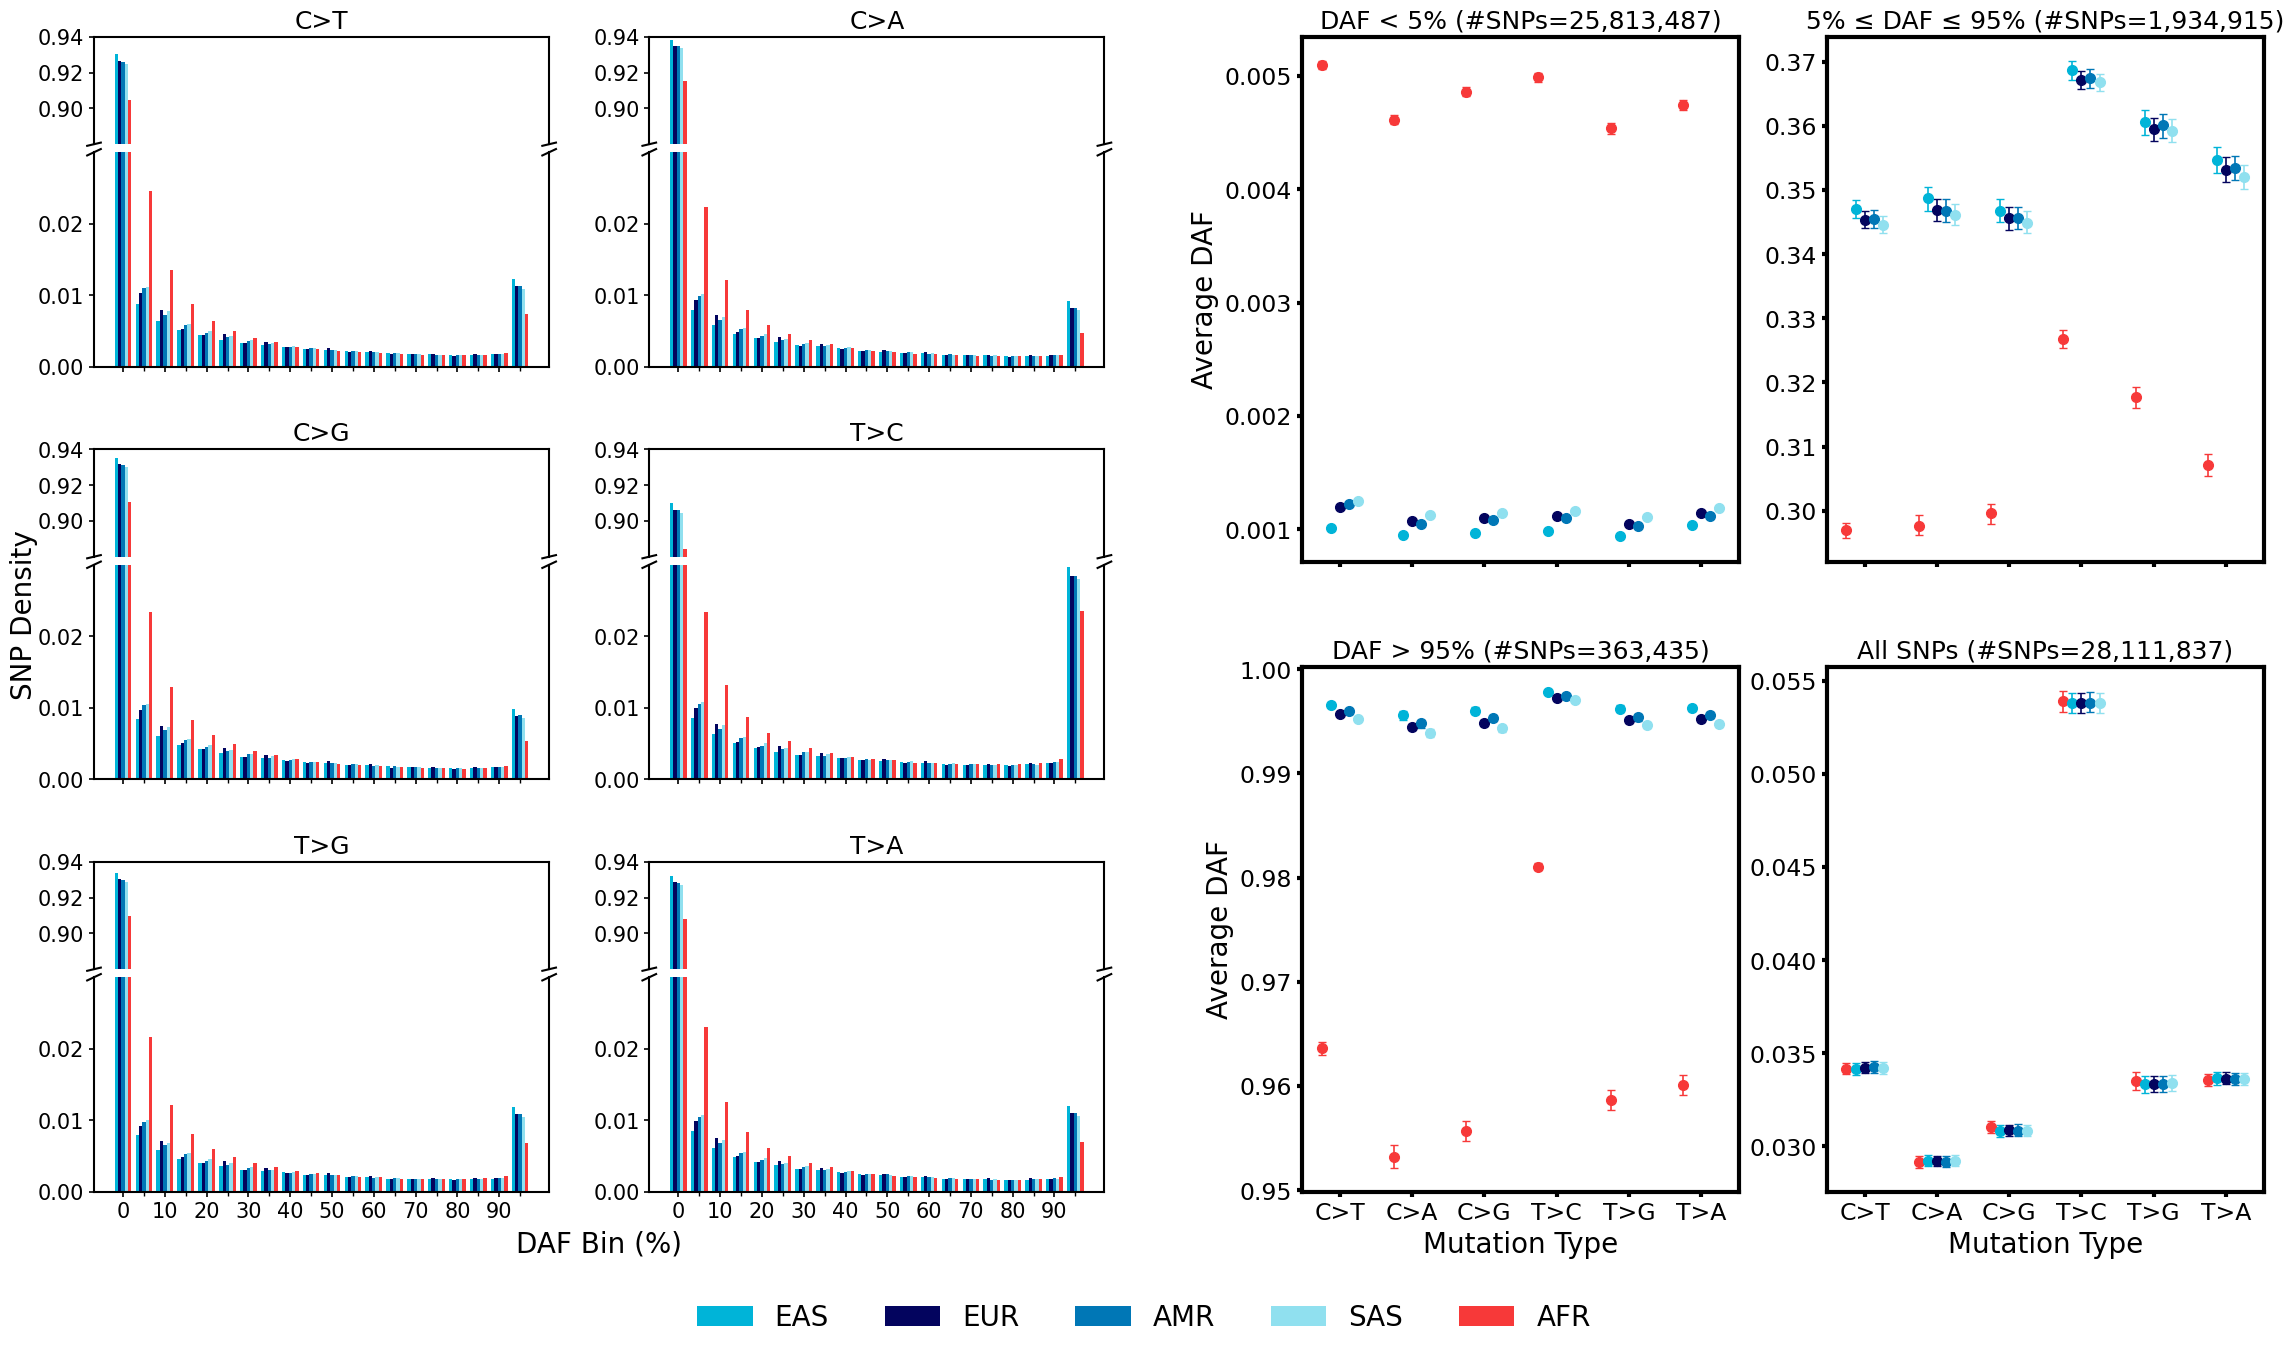

In [12]:
make_sfs_daf_figure(
    PATHS["daf_no_cpg"], daf_has_header=False, boot_path=PATHS["boot_daf_no_cpg"],
    snp_counts=(25_813_487, 1_934_915, 363_435, 28_111_837),
    save_name="FigS2.png",
)